In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score,classification_report


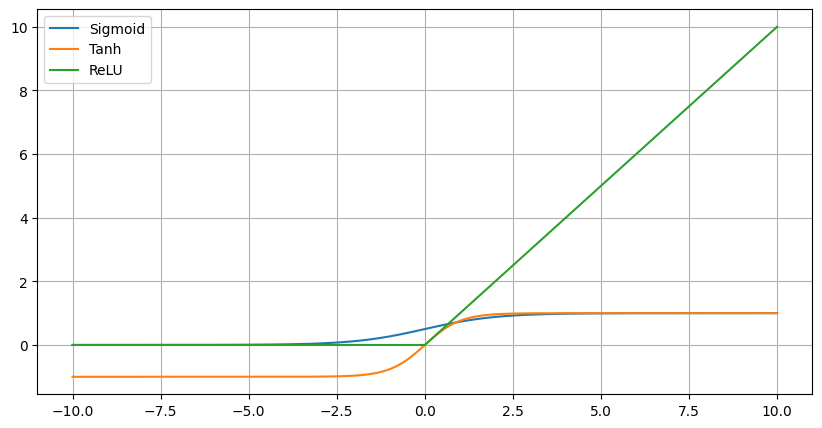

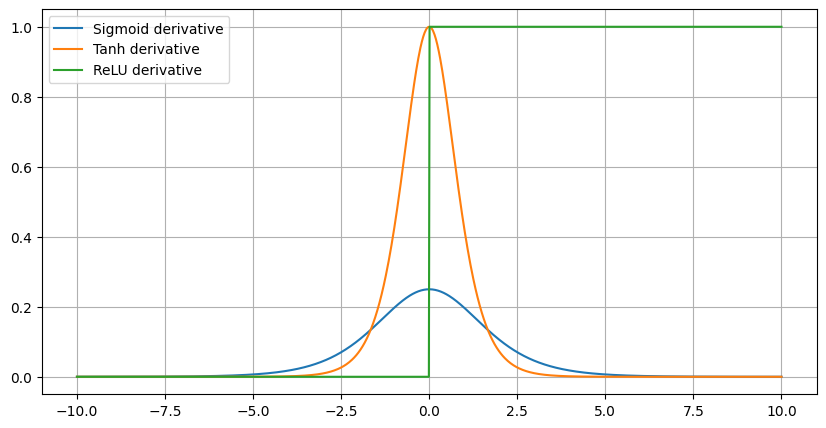

In [2]:
z = np.linspace(-10, 10, 1000)

# Activation functions
sigmoid = 1 / (1 + np.exp(-z))
tanh = np.tanh(z)
relu = np.maximum(0, z)

# Derivatives
sigmoid_derivative = sigmoid * (1 - sigmoid)
tanh_derivative = 1 - tanh**2
relu_derivative = np.where(z > 0, 1.0, 0.0)

# Plot activation functions
plt.figure(figsize=(10, 5))
plt.plot(z, sigmoid, label="Sigmoid")
plt.plot(z, tanh, label="Tanh")
plt.plot(z, relu, label="ReLU")
plt.legend()
plt.grid(True)
plt.show()

# Plot derivatives
plt.figure(figsize=(10, 5))
plt.plot(z, sigmoid_derivative, label="Sigmoid derivative")
plt.plot(z, tanh_derivative, label="Tanh derivative")
plt.plot(z, relu_derivative, label="ReLU derivative")
plt.legend()
plt.grid(True)
plt.show()

In [3]:
iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [4]:
activations = ["logistic", "tanh", "relu"]
models = {}

for activation in activations:

    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(10, 5),
            activation=activation,
            solver="adam",
            learning_rate_init=0.001,
            max_iter=5000,
            early_stopping=False,
            random_state=42
        )
    )

    model.fit(X_train, y_train)

    # Access the trained MLP inside the pipeline
    ann = model.named_steps["mlpclassifier"]

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    models[activation] = ann

    print(f"\nActivation: {activation}")
    print(f"Test accuracy: {accuracy:.4f}")
    print(f"Iterations: {ann.n_iter_}")
    print(f"Final training loss: {ann.loss_:.6f}")
    print(classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names,
        zero_division=0
    ))





Activation: logistic
Test accuracy: 0.9333
Iterations: 1861
Final training loss: 0.094796
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45


Activation: tanh
Test accuracy: 0.9333
Iterations: 1030
Final training loss: 0.062496
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45


Activation: relu
Test accuracy: 0.9556
Iterations: 704
Fina

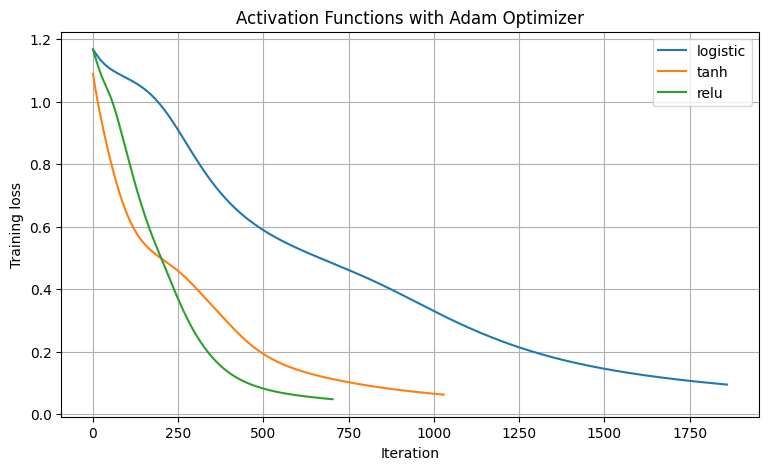

In [5]:
plt.figure(figsize=(9, 5))

for activation, ann in models.items():
    plt.plot(
        ann.loss_curve_,
        label=activation
    )

plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.title("Activation Functions with Adam Optimizer")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
import pandas as pd
from sklearn.datasets import load_iris

# Assuming 'x' is your raw NumPy array data from the Iris dataset
iris = load_iris()
x = iris.data

# The corrected line:
df = pd.DataFrame(x, columns=iris.feature_names)

print(df.head())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [12]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load the real Iris dataset
iris = load_iris()
X_raw = iris.data  # Matrix of raw numbers
y_raw = iris.target  # Class labels (0, 1, or 2)

# 2. Build the DataFrame using the correct syntax
df = pd.DataFrame(X_raw, columns=iris.feature_names)

# Add the target species labels to the DataFrame for a complete look
df["species"] = y_raw

print("--- Original Data (First 3 Rows) ---")
print(df.head(3))
print("\n" + "=" * 50 + "\n")

# 3. Separate features and split into Train/Test sets to prevent data leakage
# We will scale 'sepal length (cm)' and 'sepal width (cm)' as an example
features_to_scale = ["sepal length (cm)", "sepal width (cm)"]
X = df[features_to_scale]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 4. Initialize and apply the StandardScaler safely
scaler = StandardScaler()

# Fit and transform the training set metrics (calculates mean/std dev)
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test set using the exact same training metrics
X_test_scaled = scaler.transform(X_test)

# 5. Review the scaled metrics mapped back to a clean DataFrame structure
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=features_to_scale)
print("--- Scaled Training Features (Mean ≈ 0, Std Dev ≈ 1) ---")
print(X_train_scaled_df.head(3))


--- Original Data (First 3 Rows) ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   

   species  
0        0  
1        0  
2        0  


--- Scaled Training Features (Mean ≈ 0, Std Dev ≈ 1) ---
   sepal length (cm)  sepal width (cm)
0          -0.413416         -1.462003
1           0.551222         -0.502563
2           0.671802          0.217016


In [13]:
np.meshgrid(np.linspace(-10, 10, 1000), np.linspace(-10, 10, 1000)


_IncompleteInputError: incomplete input (813454189.py, line 1)